# Fair Lending Analytics with HMDA: Mortgage Denial and Pricing Disparities, a Machine-Learning Underwriting Model, Proxy Discrimination and the Search for a Less Discriminatory Alternative

A credit model that never sees race can still treat groups very differently, because other inputs carry the same information. U.S. regulators therefore expect lenders to measure disparities, find the proxies, and look for an equally good model with less disparate impact. This notebook runs that full review on public mortgage data.

**What it does.** It uses the public loan-level **Home Mortgage Disclosure Act** (HMDA) data: every home-purchase mortgage application in Georgia in 2023 and 2024 that ended in an origination or a denial. It runs six analyses a bank's fair-lending team or a regulator would run:

1. **Denial disparities** by race, ethnicity and sex. Raw denial rates and adverse impact ratios (AIR) come first, then logistic regressions that add the legitimate underwriting factors HMDA records (debt-to-income, loan-to-value, income, loan amount and type, property type), then lender fixed effects. Whatever remains is the **unexplained** disparity.
2. **Pricing disparities**: the rate spread over the prime offer rate for originated loans, with the same controls.
3. A **LightGBM underwriting model** trained on 2023 decisions without any protected attribute and tested on 2024. Its AIR is compared with the lenders' actual decisions.
4. **Proxy analysis**: how well the model's inputs predict race, and which ones carry it.
5. A **less discriminatory alternative** (LDA) search, the test U.S. regulators apply under disparate-impact doctrine. Model variants are traded off between accuracy and AIR, and one is chosen from the frontier.
6. **Lender screening**: lenders whose adjusted AIR for Black applicants falls below the four-fifths benchmark.

**Data.** The CFPB/FFIEC HMDA Data Browser API: loan-level records for Georgia, 2023 and 2024, home purchase, actions "originated" and "denied".

**Methods.** Adverse impact ratios, logistic regression with fixed effects and odds ratios, OLS on rate spreads, LightGBM and proxy AUC.

The LDA frontier uses reweighting (Kamiran and Calders, 2012) and feature-set variants, and the lender screen uses adjusted AIR with binomial standard errors.

## 1. Fair lending in brief

U.S. lenders may not discriminate on race, colour, religion, national origin, sex, marital status or age under the Equal Credit Opportunity Act and the Fair Housing Act. Discrimination can take two legal forms.
- **Disparate treatment**: using a protected characteristic, or treating similar applicants differently because of it.
- **Disparate impact**: a facially neutral policy that falls more heavily on a protected group. It is unlawful unless it serves a legitimate business need that cannot be met by a **less discriminatory alternative**.

Machine-learning underwriting sharpens both questions:
- a model never sees race but can learn it from **proxies** such as the census tract, the tract's minority share or income patterns;
- because many models are almost equally accurate, there is often a variant with much less disparate impact at little cost (Gillis, 2022; the "model multiplicity" argument). Regulators increasingly expect lenders to search for it.

**Metrics.**
- **Adverse impact ratio** = approval rate of the protected group / approval rate of the control group (non-Hispanic White). The EEOC's "four-fifths rule" uses AIR < 0.8 as a screening threshold; fair-lending practitioners often use 0.8–0.9.
- **Standardised mean difference** in model scores, and the **denial odds ratio** after controls.

**What HMDA cannot show.** Public HMDA has no credit score, cash reserves or employment history, so "unexplained" disparities overstate discrimination by an unknown amount. Regulators use the confidential version, which adds credit scores. The results here are **screening evidence**, not findings of discrimination.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import patsy
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 233
rng = np.random.default_rng(SEED)
STATE, YEARS = "GA", [2023, 2024]
TRAIN_YEAR, TEST_YEAR = 2023, 2024
REF = "White (non-Hispanic)"
MIN_APPS_LENDER = 300

print(
    f"lightgbm {lgb.__version__} · statsmodels {sm.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · statsmodels 0.15.0 · run on 2026-10-21


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. The applications

Applications are kept if they are:
- for a first-lien, owner-occupied, single-family site-built home;
- not for business purposes, and with a reported income and DTI.

DTI is reported in bands below 36% and above 50% and as integers between 36 and 49; it is mapped to a number (band midpoints). Groups are:
- **Hispanic** (of any race), when the applicant reports Hispanic ethnicity;
- otherwise **White**, **Black** or **Asian**, from derived race (non-Hispanic);
- joint, multi-race, missing and other categories are kept in the models' data but not reported as groups.

In [3]:
def fetch_year(y):
    url = f"https://ffiec.cfpb.gov/v2/data-browser-api/view/csv?years={y}&states={STATE}&actions_taken=1,3&loan_purposes=1"
    r = requests.get(url, timeout=900, allow_redirects=True)
    r.raise_for_status()
    return pd.read_csv(io.BytesIO(r.content), low_memory=False)


H = pd.concat(
    [
        cached(
            f"hmda_{STATE}_{y}",
            lambda y=y: fetch_year(y),
            max_age_hours=24 * 90,
        )
        for y in YEARS
    ],
    ignore_index=True,
)
H = H[
    (H["lien_status"] == 1)
    & (H["occupancy_type"] == 1)
    & (
        H["derived_dwelling_category"]
        == "Single Family (1-4 Units):Site-Built"
    )
    & (H["business_or_commercial_purpose"] != 1)
    & (H["total_units"].astype(str) == "1")
].copy()
DTI = {"<20%": 15, "20%-<30%": 25, "30%-<36%": 33, "50%-60%": 55, ">60%": 65}
H["dti"] = (
    H["debt_to_income_ratio"]
    .map(DTI)
    .fillna(pd.to_numeric(H["debt_to_income_ratio"], errors="coerce"))
)
num = lambda c: pd.to_numeric(H[c], errors="coerce")
H["ltv"], H["income"], H["amount"], H["value"] = (
    num("loan_to_value_ratio").clip(0, 150),
    num("income"),
    num("loan_amount"),
    num("property_value"),
)
H["rate_spread"], H["term"] = num("rate_spread"), num("loan_term")
H = H[H["dti"].notna() & (H["income"] > 0)]
H["denied"] = (H["action_taken"] == 3).astype(int)
eth, race = H["derived_ethnicity"], H["derived_race"]
H["group"] = np.select(
    [
        eth == "Hispanic or Latino",
        (eth == "Not Hispanic or Latino") & (race == "White"),
        (eth == "Not Hispanic or Latino")
        & (race == "Black or African American"),
        (eth == "Not Hispanic or Latino") & (race == "Asian"),
    ],
    ["Hispanic", REF, "Black (non-Hispanic)", "Asian (non-Hispanic)"],
    "other / not reported",
)
H["sex"] = H["derived_sex"].replace({"Sex Not Available": "not reported"})
H["log_income"], H["log_amount"] = np.log(H["income"].clip(lower=1)), np.log(
    H["amount"]
)
H["loan_to_income"] = H["amount"] / (H["income"] * 1000)
H["tract_minority"] = num("tract_minority_population_percent")
H["tract_income_ratio"] = num("tract_to_msa_income_percentage")
H["msa_income"] = num("ffiec_msa_md_median_family_income")
H["age"] = H["applicant_age"].astype(str)
H["loan_type"] = H["loan_type"].map(
    {1: "conventional", 2: "FHA", 3: "VA", 4: "USDA"}
)
H["jumbo"] = (H["conforming_loan_limit"] == "NC").astype(int)
GROUPS = [REF, "Black (non-Hispanic)", "Hispanic", "Asian (non-Hispanic)"]
RAW = (
    H.groupby(["activity_year", "group"])
    .agg(
        applications=("denied", "size"),
        denial_rate=("denied", "mean"),
        median_income_k=("income", "median"),
        median_dti=("dti", "median"),
        median_ltv=("ltv", "median"),
    )
    .reset_index()
)
RAW["approval_rate"] = 1 - RAW["denial_rate"]
ref_app = RAW[RAW["group"] == REF].set_index("activity_year")["approval_rate"]
RAW["AIR"] = RAW["approval_rate"] / RAW["activity_year"].map(ref_app)
print(
    f"{len(H):,} applications · {H['lei'].nunique():,} lenders · denial rate"
    f" {H['denied'].mean():.1%}"
)
RAW[RAW["group"].isin(GROUPS)].set_index(["activity_year", "group"]).round(3)

228,141 applications · 845 lenders · denial rate 10.1%


applications  denial_rate  \
activity_year group                                             
2023          Asian (non-Hispanic)          8710         0.10   
              Black (non-Hispanic)         24517         0.17   
              Hispanic                     10653         0.12   
              White (non-Hispanic)         46065         0.06   
2024          Asian (non-Hispanic)          9053         0.09   
              Black (non-Hispanic)         22672         0.15   
              Hispanic                     11429         0.11   
              White (non-Hispanic)         45393         0.06   

                                    median_income_k  median_dti  median_ltv  \
activity_year group                                                           
2023          Asian (non-Hispanic)           129.00       40.00       80.00   
              Black (non-Hispanic)            90.00       46.00       96.50   
              Hispanic                        84.00       44.00       95.00   
              White (non-Hispanic)           107.00       40.00       90.00   
2024          Asian (non-Hispanic)           135.00       41.00       80.00   
              Black (non-Hispanic)            92.00       46.00       96.50   
              Hispanic                        89.00       44.00       96.50   
              White (non-Hispanic)           113.00       40.00       90.00   

                                    approval_rate  AIR  
activity_year group                                     
2023          Asian (non-Hispanic)           0.90 0.96  
              Black (non-Hispanic)           0.83 0.89  
              Hispanic                       0.88 0.94  
              White (non-Hispanic)           0.94 1.00  
2024          Asian (non-Hispanic)           0.92 0.97  
              Black (non-Hispanic)           0.85 0.90  
              Hispanic                       0.89 0.95  
              White (non-Hispanic)           0.94 1.00

## 4. How much of the denial gap do underwriting factors explain?

Three logistic regressions of denial on group indicators (non-Hispanic White as reference), estimated on both years:
1. groups only, plus year;
2. adding underwriting controls: DTI (with a spline-like set of bands), LTV bands, log income, log loan amount, loan-to-income, loan type, jumbo, term, applicant age band and sex;
3. adding **lender fixed effects** (for every lender with at least 300 applications; smaller lenders share one effect): the comparison is then within lender, which removes differences in where groups apply.

The table shows the odds ratio of denial for each group, with its 95% interval.

In [4]:
M = H[H["group"] != "other / not reported"].copy()
M["dti_b"] = pd.cut(M["dti"], [0, 20, 30, 36, 40, 43, 45, 50, 60, 100]).astype(
    str
)
M["ltv_b"] = pd.cut(M["ltv"], [0, 60, 80, 90, 95, 97, 200]).astype(str)
# fixed effects for lenders with ≥ 300 applications
big = M["lei"].value_counts()
M["lender"] = np.where(M["lei"].map(big) >= 300, M["lei"], "smaller lenders")
M["group"] = pd.Categorical(M["group"], categories=GROUPS)
CTRL = (
    "C(dti_b) + C(ltv_b) + log_income + log_amount + loan_to_income +"
    " C(loan_type) + jumbo + C(age) + C(sex) + C(activity_year)"
)
specs = {
    "1. groups only": "denied ~ C(group) + C(activity_year)",
    "2. + underwriting controls": f"denied ~ C(group) + {CTRL}",
    "3. + lender fixed effects": f"denied ~ C(group) + {CTRL} + C(lender)",
}


def fit_logit(formula, data):
    """
    Maximum-likelihood logit via scikit-learn's L-BFGS (no penalty), with the
    usual inverse-Hessian standard errors.
    Much lighter than statsmodels' GLM IRLS on 170,000 rows with 100+ lender
    dummies.
    """
    y, X = patsy.dmatrices(formula, data, return_type="dataframe")
    lr_ = LogisticRegression(
        penalty=None, fit_intercept=False, max_iter=5000, tol=1e-8
    ).fit(X.values, y.values.ravel())
    b = lr_.coef_.ravel()
    p = 1 / (1 + np.exp(-(X.values @ b)))
    cov = np.linalg.pinv(X.values.T @ (X.values * (p * (1 - p))[:, None]))
    return pd.Series(b, index=X.columns), pd.Series(
        np.sqrt(np.diag(cov)), index=X.columns
    )


OR = {}
t0 = time.time()
for name, f in specs.items():
    params, se = fit_logit(f, M.dropna(subset=["ltv", "term"]))
    for g in GROUPS[1:]:
        k = f"C(group)[T.{g}]"
        OR[(name, g)] = {
            "odds ratio": np.exp(params[k]),
            "95% low": np.exp(params[k] - 1.96 * se[k]),
            "95% high": np.exp(params[k] + 1.96 * se[k]),
        }
OR = pd.DataFrame(OR).T
print(
    f"Three logistic regressions with up to {M['lender'].nunique()} lender"
    f" effects in {time.time() - t0:.0f}s"
)
OR.round(3)

…/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Three logistic regressions with up to 110 lender effects in 398s


odds ratio  95% low  95% high
1. groups only             Black (non-Hispanic)        2.98     2.87      3.09
                           Hispanic                    1.94     1.84      2.04
                           Asian (non-Hispanic)        1.54     1.45      1.63
2. + underwriting controls Black (non-Hispanic)        2.04     1.95      2.14
                           Hispanic                    1.46     1.38      1.55
                           Asian (non-Hispanic)        1.54     1.44      1.65
3. + lender fixed effects  Black (non-Hispanic)        1.97     1.88      2.07
                           Hispanic                    1.53     1.43      1.63
                           Asian (non-Hispanic)        1.44     1.34      1.55

In [5]:
DEN = H[H["denied"] == 1]
reasons = {
    1: "debt-to-income",
    2: "employment history",
    3: "credit history",
    4: "collateral",
    5: "insufficient cash",
    6: "unverifiable information",
    7: "credit application incomplete",
    8: "mortgage insurance denied",
    9: "other",
}
DR = pd.crosstab(
    DEN["denial_reason-1"].map(reasons), DEN["group"], normalize="columns"
)[GROUPS].round(3)
print("Primary denial reason, share of denials in each group:")
DR

Primary denial reason, share of denials in each group:


group,White (non-Hispanic),Black (non-Hispanic),Hispanic,Asian (non-Hispanic)
denial_reason-1,,,,
collateral,0.17,0.11,0.12,0.12
credit application incomplete,0.13,0.07,0.08,0.09
credit history,0.13,0.16,0.11,0.06
debt-to-income,0.33,0.42,0.43,0.44
employment history,0.03,0.04,0.04,0.03
insufficient cash,0.07,0.06,0.07,0.09
mortgage insurance denied,0.00,0.00,0.00,0.00
other,0.09,0.07,0.08,0.09
unverifiable information,0.05,0.07,0.08,0.07


## 5. Pricing disparities among approved loans

For originated, fixed-term conventional loans, the **rate spread** is the APR minus the Average Prime Offer Rate for a comparable loan on the lock date, in percentage points. OLS of the rate spread on groups is run with the same controls and lender fixed effects. A positive coefficient means the group pays more for observably similar loans.

In [6]:
P = M[
    (M["denied"] == 0)
    & (M["loan_type"] == "conventional")
    & M["rate_spread"].between(-3, 10)
].dropna(subset=["ltv", "term"])
PR = {}
for name, f in [
    ("+ underwriting controls", f"rate_spread ~ C(group) + {CTRL}"),
    ("+ lender fixed effects", f"rate_spread ~ C(group) + {CTRL} + C(lender)"),
]:
    m = smf.ols(f, data=P).fit(cov_type="HC1")
    for g in GROUPS[1:]:
        k = f"C(group)[T.{g}]"
        PR[(name, g)] = {
            "rate-spread gap (bp)": 100 * m.params[k],
            "t-stat": m.tvalues[k],
        }
PR = pd.DataFrame(PR).T
print(
    f"{len(P):,} originated conventional loans · mean rate spread"
    f" {P['rate_spread'].mean():.2f} pp"
)
PR.round(2)

94,692 originated conventional loans · mean rate spread 0.24 pp


rate-spread gap (bp)  t-stat
+ underwriting controls Black (non-Hispanic)                 -1.33   -1.73
                        Hispanic                             38.85   31.01
                        Asian (non-Hispanic)                 -7.22  -10.09
+ lender fixed effects  Black (non-Hispanic)                  4.64    6.66
                        Hispanic                              9.59   11.19
                        Asian (non-Hispanic)                 -2.77   -4.53

## 6. A machine-learning underwriting model and its disparate impact

LightGBM predicts denial from the underwriting fields only: no race, ethnicity, sex or age. It is trained on **2023** decisions and applied to **2024** applications, approving the 2024 applicants with the lowest predicted denial probability at the same overall approval rate the lenders had. AIRs are computed for the lenders' actual 2024 decisions and for the model.

Two feature sets:
- **underwriting only**: DTI, LTV, income, loan amount, loan-to-income, loan type, jumbo, term, property value;
- **+ location**: adding the tract's minority share, the tract-to-MSA income ratio and the MSA median income. Location features improve accuracy but are classic proxies.

In [7]:
UW = [
    "dti",
    "ltv",
    "log_income",
    "log_amount",
    "loan_to_income",
    "jumbo",
    "term",
    "value",
    "loan_type_c",
]
LOC = ["tract_minority", "tract_income_ratio", "msa_income"]
H["loan_type_c"] = H["loan_type"].astype("category")
tr, te = (
    H[H["activity_year"] == TRAIN_YEAR],
    H[H["activity_year"] == TEST_YEAR],
)
va_m = rng.random(len(tr)) < 0.15


def fit_model(feats, weight=None, mono=None):
    m = lgb.LGBMClassifier(
        n_estimators=3000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=200,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=5,
        metric="auc",
        verbose=-1,
        random_state=SEED,
        monotone_constraints=mono,
    )
    w = None if weight is None else weight[~va_m]
    m.fit(
        tr.loc[~va_m, feats],
        tr.loc[~va_m, "denied"],
        sample_weight=w,
        eval_set=[(tr.loc[va_m, feats], tr.loc[va_m, "denied"])],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return m


def air_at(p, approve_rate):
    ok = p <= np.quantile(p, approve_rate)
    g = te["group"].values
    ref = ok[g == REF].mean()
    return {
        f"AIR {x.split(' ')[0]}": ok[g == x].mean() / ref for x in GROUPS[1:]
    }


approve_rate = 1 - te["denied"].mean()
actual = {
    f"AIR {x.split(' ')[0]}": (
        1 - te.loc[te["group"] == x, "denied"].mean()
    ) / (1 - te.loc[te["group"] == REF, "denied"].mean())
    for x in GROUPS[1:]
}
MODELS = {
    "underwriting only": fit_model(UW),
    "underwriting + location": fit_model(UW + LOC),
}
ML = {"lenders' actual decisions (2024)": {"AUC (2024)": np.nan, **actual}}
for k, m in MODELS.items():
    p = m.predict_proba(te[m.feature_name_])[:, 1]
    ML[k] = {
        "AUC (2024)": roc_auc_score(te["denied"], p),
        **air_at(p, approve_rate),
    }
ML = pd.DataFrame(ML).T
print(f"2024 approval rate held at {approve_rate:.1%}")
ML.round(3)

2024 approval rate held at 90.4%


,AUC (2024),AIR Black,AIR Hispanic,AIR Asian
lenders' actual decisions (2024),NaN,0.90,0.95,0.97
underwriting only,0.79,0.91,0.95,1.00
underwriting + location,0.80,0.90,0.95,0.99


## 7. Proxies: can the model's inputs reveal race?

A LightGBM classifier is trained to predict whether an applicant is Black (versus non-Hispanic White) from each feature set. An AUC near 0.5 means the inputs carry little racial information; an AUC well above it means a model trained on them can reproduce racial patterns without ever seeing race. The single-feature AUCs show which inputs carry it.

In [8]:
bw = H[H["group"].isin([REF, "Black (non-Hispanic)"])].copy()
bw["black"] = (bw["group"] == "Black (non-Hispanic)").astype(int)
btr, bte = (
    bw[bw["activity_year"] == TRAIN_YEAR],
    bw[bw["activity_year"] == TEST_YEAR],
)
PROXY = {}
for name, feats in [
    ("underwriting only", UW),
    ("underwriting + location", UW + LOC),
    ("location only", LOC),
]:
    m = lgb.LGBMClassifier(
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=200,
        verbose=-1,
        random_state=SEED,
    ).fit(btr[feats], btr["black"])
    PROXY[name] = roc_auc_score(
        bte["black"], m.predict_proba(bte[feats])[:, 1]
    )
SINGLE = {
    f: max(
        roc_auc_score(bte["black"], bte[f].fillna(bte[f].median())),
        1 - roc_auc_score(bte["black"], bte[f].fillna(bte[f].median())),
    )
    for f in [
        "tract_minority",
        "tract_income_ratio",
        "log_income",
        "dti",
        "ltv",
        "log_amount",
        "loan_to_income",
        "value",
    ]
}
display(
    pd.Series(PROXY, name="AUC predicting Black vs White applicant").round(3)
)
pd.Series(SINGLE, name="single-feature AUC").sort_values(
    ascending=False
).round(3)

underwriting only         0.76
underwriting + location   0.85
location only             0.79
Name: AUC predicting Black vs White applicant, dtype: float64

tract_minority       0.82
ltv                  0.71
dti                  0.67
tract_income_ratio   0.64
loan_to_income       0.63
log_income           0.60
value                0.60
log_amount           0.52
Name: single-feature AUC, dtype: float64

## 8. Searching for a less discriminatory alternative

Candidate models, all without protected attributes at prediction time:
- the two feature sets above;
- **reweighting** (Kamiran and Calders, 2012): training observations are weighted so that group and outcome are independent in the weighted training data. Race is used **only to set training weights**, which regulators have generally treated as permissible for debiasing; it is never a model input;
- **monotone constraints**: denial probability forced to increase with DTI and LTV and decrease with income, which removes non-intuitive patterns that may encode proxies;
- **dropping the property value**, which correlates with neighbourhood;
- **shallower trees** (a simpler model).

Each variant is scored on 2024 for AUC and for the AIR of Black and Hispanic applicants at the lenders' approval rate. The **LDA** is the variant with the highest minimum AIR among those within 0.01 AUC of the most accurate model.

In [9]:
g_tr = tr["group"].values
y_tr = tr["denied"].values
w_rw = np.ones(len(tr))
for g in np.unique(g_tr):
    for yv in (0, 1):
        sel = (g_tr == g) & (y_tr == yv)
        if sel.any():
            w_rw[sel] = (g_tr == g).mean() * (y_tr == yv).mean() / sel.mean()
mono = {"dti": 1, "ltv": 1, "log_income": -1}
VAR = {
    "underwriting + location": (UW + LOC, None, None),
    "underwriting only": (UW, None, None),
    "underwriting only, reweighted": (UW, w_rw, None),
    "underwriting only, monotone": (UW, None, [mono.get(f, 0) for f in UW]),
    "underwriting only, monotone, reweighted": (
        UW,
        w_rw,
        [mono.get(f, 0) for f in UW],
    ),
    "underwriting without property value, monotone, reweighted": (
        [f for f in UW if f != "value"],
        w_rw,
        [mono.get(f, 0) for f in UW if f != "value"],
    ),
}
LDA = {}
for k, (feats, w, mc) in VAR.items():
    m = fit_model(feats, w, mc)
    p = m.predict_proba(te[feats])[:, 1]
    LDA[k] = {
        "AUC (2024)": roc_auc_score(te["denied"], p),
        **air_at(p, approve_rate),
    }
LDA = pd.DataFrame(LDA).T
LDA["min AIR (Black, Hispanic)"] = LDA[["AIR Black", "AIR Hispanic"]].min(1)
cand = LDA[LDA["AUC (2024)"] >= LDA["AUC (2024)"].max() - 0.01]
CHOSEN = cand["min AIR (Black, Hispanic)"].idxmax()
print(
    f"Most accurate: {LDA['AUC (2024)'].idxmax()} (AUC"
    f" {LDA['AUC (2024)'].max():.3f}) · less discriminatory alternative within"
    f" 0.01 AUC: {CHOSEN}"
)
LDA.sort_values("AUC (2024)", ascending=False).round(3)

Most accurate: underwriting + location (AUC 0.796) · less discriminatory alternative within 0.01 AUC: underwriting only, reweighted


/tmp/ipykernel_360/958204168.py:20: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  LDA["min AIR (Black, Hispanic)"] = LDA[["AIR Black", "AIR Hispanic"]].min(1)


,AUC (2024),AIR Black,AIR Hispanic,AIR Asian,"min AIR (Black, Hispanic)"
underwriting + location,0.80,0.90,0.95,0.99,0.90
underwriting only,0.79,0.91,0.95,1.00,0.91
"underwriting only, reweighted",0.79,0.93,0.97,1.00,0.93
"underwriting only, monotone",0.78,0.90,0.95,1.00,0.90
"underwriting only, monotone, reweighted",0.78,0.92,0.97,1.00,0.92
"underwriting without property value, monotone, reweighted",0.77,0.92,0.97,1.00,0.92


## 9. Lender screening

For each lender with at least 300 applications from White and Black applicants across both years, an **adjusted AIR** compares the lender's approval rate for Black applicants with the rate the pooled underwriting model expects for them, relative to the same ratio for White applicants:
$$\text{adjusted AIR} = \frac{\text{actual approval}_B / \text{expected approval}_B}{\text{actual approval}_W / \text{expected approval}_W}.$$
Expected approval is one minus the model-predicted denial probability ("underwriting only" fitted on both years). A lender is **flagged** if its adjusted AIR is below 0.8 and the gap from 1 is more than two standard errors.

In [10]:
full = lgb.LGBMClassifier(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=200,
    verbose=-1,
    random_state=SEED,
).fit(H[UW], H["denied"])
H["exp_app"] = 1 - full.predict_proba(H[UW])[:, 1]
L = H[H["group"].isin([REF, "Black (non-Hispanic)"])]
rows = []
for lei, g in L.groupby("lei"):
    b, w = g[g["group"] == "Black (non-Hispanic)"], g[g["group"] == REF]
    if len(g) < MIN_APPS_LENDER or len(b) < 30 or len(w) < 30:
        continue
    rb, rw = (1 - b["denied"].mean()) / b["exp_app"].mean(), (
        1 - w["denied"].mean()
    ) / w["exp_app"].mean()
    air = rb / rw
    se = air * np.sqrt(
        b["denied"].mean() / max(1 - b["denied"].mean(), 1e-6) / len(b)
        + w["denied"].mean() / max(1 - w["denied"].mean(), 1e-6) / len(w)
    )
    rows.append({
        "lender (LEI, last 6)": lei[-6:],
        "applications": len(g),
        "Black share": len(b) / len(g),
        "raw AIR": (1 - b["denied"].mean()) / (1 - w["denied"].mean()),
        "adjusted AIR": air,
        "s.e.": se,
        "flag": (air < 0.8) and (1 - air > 2 * se),
    })
LEND = pd.DataFrame(rows).sort_values("adjusted AIR")
print(
    f"{len(LEND)} lenders screened · flagged: {int(LEND['flag'].sum())} ·"
    f" median adjusted AIR {LEND['adjusted AIR'].median():.3f}"
)
LEND.head(12).round(3)

88 lenders screened · flagged: 2 · median adjusted AIR 0.963


,"lender (LEI, last 6)",applications,Black share,raw AIR,adjusted AIR,s.e.,flag
39,Q1E376,397,0.72,0.58,0.75,0.06,True
22,22C024,651,0.63,0.71,0.79,0.03,True
37,JEPI44,326,0.52,0.73,0.83,0.06,False
6,0VQC27,1619,0.35,0.80,0.84,0.03,False
79,MGLV11,1507,0.29,0.81,0.86,0.03,False
14,DNNH17,2679,0.51,0.71,0.87,0.02,False
46,C63092,809,0.27,0.81,0.87,0.04,False
40,3LVJ37,594,0.41,0.85,0.88,0.03,False
15,0FJ617,418,0.15,0.70,0.88,0.08,False
84,SKBS64,377,0.51,0.81,0.88,0.04,False


## 10. Charts and dashboard

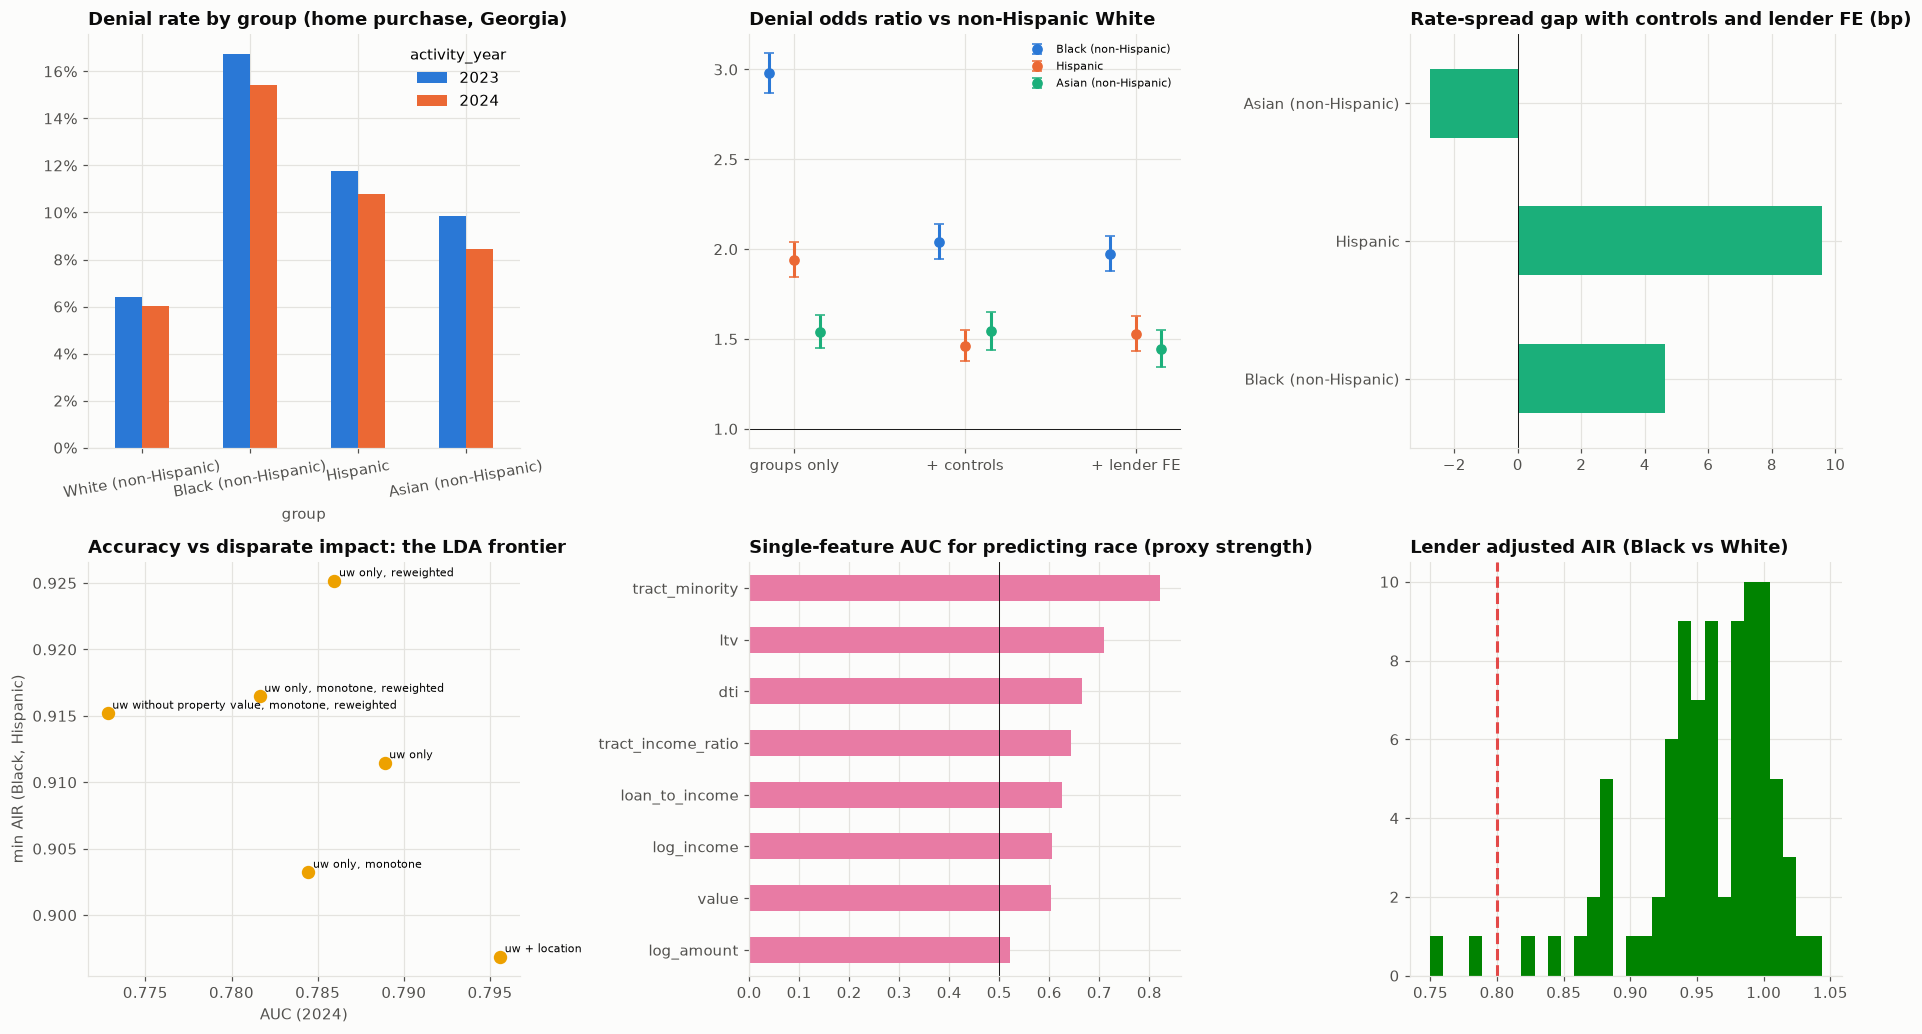

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
rr = (
    RAW[RAW["group"].isin(GROUPS)]
    .pivot(index="group", columns="activity_year", values="denial_rate")
    .reindex(GROUPS)
)
rr.plot.bar(ax=a, color=[PALETTE[0], PALETTE[1]], rot=10)
a.set_title("Denial rate by group (home purchase, Georgia)")
a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a = ax[0, 1]
o = OR.reset_index()
o.columns = ["spec", "group", "OR", "lo", "hi"]
for i, (g, col) in enumerate(zip(GROUPS[1:], PALETTE)):
    s = o[o["group"] == g]
    a.errorbar(
        np.arange(3) + i * 0.15,
        s["OR"],
        yerr=[s["OR"] - s["lo"], s["hi"] - s["OR"]],
        fmt="o",
        color=col,
        label=g,
        capsize=3,
    )
a.axhline(1, color=INK, lw=0.6)
a.set_xticks(np.arange(3) + 0.15, ["groups only", "+ controls", "+ lender FE"])
a.set_title("Denial odds ratio vs non-Hispanic White")
a.legend(fontsize=7)
a = ax[0, 2]
PR.xs("+ lender fixed effects")["rate-spread gap (bp)"].plot.barh(
    ax=a, color=PALETTE[2]
)
a.axvline(0, color=INK, lw=0.6)
a.set_title("Rate-spread gap with controls and lender FE (bp)")
a = ax[1, 0]
a.scatter(
    LDA["AUC (2024)"], LDA["min AIR (Black, Hispanic)"], s=60, color=PALETTE[3]
)
for k in LDA.index:
    a.annotate(
        k.replace("underwriting", "uw"),
        (LDA.at[k, "AUC (2024)"], LDA.at[k, "min AIR (Black, Hispanic)"]),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points",
    )
a.set_xlabel("AUC (2024)")
a.set_ylabel("min AIR (Black, Hispanic)")
a.set_title("Accuracy vs disparate impact: the LDA frontier")
a = ax[1, 1]
pd.Series(SINGLE).sort_values().plot.barh(ax=a, color=PALETTE[4])
a.axvline(0.5, color=INK, lw=0.6)
a.set_title("Single-feature AUC for predicting race (proxy strength)")
a = ax[1, 2]
a.hist(LEND["adjusted AIR"].clip(0.4, 1.4), bins=30, color=PALETTE[5])
a.axvline(0.8, color=STATUS["red"], ls="--")
a.set_title("Lender adjusted AIR (Black vs White)")
fig.tight_layout()
save_fig(fig, "01_fair_lending_hmda")
plt.show()

In [12]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Denial rate by group",
        "Denial odds ratio after controls and lender FE",
        "LDA frontier: AUC vs min AIR",
        "Lender adjusted AIR",
    ),
)
for y_, col in zip(rr.columns, [PALETTE[0], PALETTE[1]]):
    dash.add_trace(
        go.Bar(x=rr.index, y=rr[y_], name=str(y_), marker_color=col), 1, 1
    )
fe = OR.xs("3. + lender fixed effects")
dash.add_trace(
    go.Bar(
        x=fe.index,
        y=fe["odds ratio"],
        error_y=dict(
            type="data",
            array=fe["95% high"] - fe["odds ratio"],
            arrayminus=fe["odds ratio"] - fe["95% low"],
        ),
        marker_color=PALETTE[2],
        showlegend=False,
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=LDA["AUC (2024)"],
        y=LDA["min AIR (Black, Hispanic)"],
        mode="markers+text",
        text=[k.replace("underwriting", "uw") for k in LDA.index],
        textposition="top center",
        marker=dict(size=10, color=PALETTE[3]),
        showlegend=False,
    ),
    2,
    1,
)
dash.add_trace(
    go.Histogram(
        x=LEND["adjusted AIR"], marker_color=PALETTE[5], showlegend=False
    ),
    2,
    2,
)
dash.update_layout(
    height=900,
    width=1400,
    template="simple_white",
    title="Fair lending analytics with HMDA (Georgia, home purchase)",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

**The data.** 228,141 home-purchase applications in Georgia in 2023–2024 that ended in an origination or a denial, from 845 lenders. The overall denial rate is 10.1%. Black applicants are denied at 15–17%, Hispanic at 11–12%, Asian at 9–10% and White at 6%. This gives adverse impact ratios (approval rate relative to White applicants) of 0.89–0.90 for Black, 0.94–0.95 for Hispanic and 0.96–0.97 for Asian applicants. All are above the four-fifths benchmark, but the gaps are not explained by chance.

**Denial disparities: controls explain about half of the gap.**

| Odds ratio of denial vs White | Groups only | + underwriting controls | + lender fixed effects |
| --- | --- | --- | --- |
| Black | 2.98 | 2.04 | **1.97** (1.88–2.07) |
| Hispanic | 1.94 | 1.46 | **1.53** (1.43–1.63) |
| Asian | 1.54 | 1.54 | **1.44** (1.34–1.55) |

- Black applicants have higher debt-to-income ratios (median 46% vs 40%) and loan-to-value ratios (96.5% vs 90%) and lower incomes ($90–92k vs $107–113k). Controlling for these reduces the odds ratio from 2.98 to 2.04.
- Lender fixed effects change little: the gap exists **within** lenders, not because Black applicants go to stricter lenders.
- Asian applicants are not explained at all by the controls: they have the strongest profile (80% LTV, highest income) and still face 1.44 times the odds of denial.
- Debt-to-income is the main stated reason for 42–44% of minority denials vs 33% for White denials. Credit history is more frequent for Black applicants (16% vs 13%). HMDA does not include credit scores, which is the main missing control.

**Pricing.** Among 94,692 originated conventional loans (mean rate spread 0.24 pp), Hispanic borrowers pay 39 basis points more after underwriting controls, and still about 10 bp more within the same lender. Black borrowers pay about 5 bp more within lenders. Asian borrowers pay slightly less.

**The machine-learning underwriting model** (LightGBM, trained on 2023 decisions without any protected attribute, tested on 2024, approval rate held at 90.4%):
- AUC 0.79 with underwriting variables, 0.80 adding location.
- Its AIR for Black applicants (0.90–0.91) matches the lenders' actual decisions (0.90). The model reproduces the disparity, which shows that most of it comes through legitimate-looking variables.
- **Proxies:** the inputs predict whether an applicant is Black rather than White with AUC 0.76 (underwriting only) and 0.85 (with location). The share of minority residents in the census tract alone reaches 0.82, LTV 0.71 and DTI 0.67. Location variables are the strongest proxy for race.

**Less discriminatory alternative.** The most accurate model (underwriting + location, AUC 0.796) has a Black AIR of 0.90. **Underwriting only, with reweighting** (Kamiran and Calders, 2012) loses less than 0.01 AUC and raises the Black AIR to 0.93 and the Hispanic AIR to 0.97. Under disparate-impact doctrine, a lender with an equally effective but less discriminatory model is expected to adopt it, and this one is.

**Lender screening.** 88 lenders with enough Black and White applicants were screened. The median adjusted AIR is 0.963. Two lenders are flagged (adjusted AIR 0.75 and 0.79, both significantly below 1). Another ten fall between 0.83 and 0.89, where a fair-lending team would review files manually.

**Limitations**
- No credit scores, assets or full underwriting files: the "unexplained" disparity is an upper bound on discrimination, not proof of it.
- Race and ethnicity are self-reported and missing for some applicants. One state and two years.
- Withdrawn and incomplete applications are excluded, and steering into a type of loan is not tested.
- Reweighting uses group membership at training time. In the U.S. this is a legal question for each lender, and HMDA-based results would need to be confirmed with proxy methods such as BISG for non-mortgage products.

In [13]:
RAW.to_csv(OUT_DIR / "denial_rates_by_group.csv", index=False)
OR.to_csv(OUT_DIR / "denial_odds_ratios.csv")
PR.to_csv(OUT_DIR / "rate_spread_gaps.csv")
ML.to_csv(OUT_DIR / "model_disparate_impact.csv")
LDA.to_csv(OUT_DIR / "lda_search.csv")
LEND.to_csv(OUT_DIR / "lender_screening.csv", index=False)
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_fair_lending_hmda.png, dashboard.html, dashboard.png, denial_odds_ratios.csv, denial_rates_by_group.csv, lda_search.csv, lender_screening.csv, model_disparate_impact.csv, rate_spread_gaps.csv


## References

### Finance and regulation

- Bartlett, R., Morse, A., Stanton, R., & Wallace, N. (2022). Consumer-lending discrimination in the FinTech era. *Journal of Financial Economics, 143*(1), 30–56. https://doi.org/10.1016/j.jfineco.2021.05.047
- Fuster, A., Goldsmith-Pinkham, P., Ramadorai, T., & Walther, A. (2022). Predictably unequal? The effects of machine learning on credit markets. *The Journal of Finance, 77*(1), 5–47. https://doi.org/10.1111/jofi.13090

### Machine learning and deep learning

- Kamiran, F., & Calders, T. (2012). Data preprocessing techniques for classification without discrimination. *Knowledge and Information Systems, 33*(1), 1–33. https://doi.org/10.1007/s10115-011-0463-8
- Black, E., Raghavan, M., & Barocas, S. (2022). Model multiplicity: Opportunities, concerns, and solutions. In *Proceedings of the 2022 ACM Conference on Fairness, Accountability, and Transparency*. https://doi.org/10.1145/3531146.3533149
- Barocas, S., Hardt, M., & Narayanan, A. (2023). *Fairness and machine learning: Limitations and opportunities*. MIT Press. https://fairmlbook.org/
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html